# 08 · 年齢だけのモデルは較正されているか

画像モデルの主要な問題は「AUC は保たれるが、較正が崩れる」ことだった（分布外 ECE 0.104、LOSO-B 0.162）。
一方、画像を使わない年齢 1 変数のロジスティック回帰は、分布外の AUC で画像モデルを上回った（0.889 対 0.860、
`results/age_prior.json` の `auc_table`）。ただしその比較は **AUC だけ**で、年齢モデルの較正は測っていなかった。

ここでは 3 つのスコアを、同じ 9 ユニット（分布外 4・分布内 5）で較正の指標まで並べる。

| スコア | 定義 |
|---|---|
| 年齢のみ | 年齢 1 変数のロジスティック回帰（罰則なし）。各ユニットの訓練側で当て、test の年齢に適用 |
| 画像モデル | 融合後の p̂ = α / (α + β)。3 seed |
| 画像 + 年齢 | z + [logit π(a) − logit ȳ_train]。`auc_table` と同じ足し算で、学習し直したモデルではない |

どのスコアも目標施設のラベルは使わない。指標は AUC、ECE（10 等幅ビン、`openidh_model.eval.metrics` と同じ定義）、NLL、Brier、
平均予測、**較正切片**（傾き 1 のままロジットに足すべき量。正 = 過小評価）、**較正スロープ**（a + s·logit p の s。1 未満 = 過信）。

ロジックは `scripts/age_baseline_calibration.py`（この notebook はそれを import して使う）。
既存の結果ファイルは読むだけで、上書きしない。

In [1]:
boot_reps = 1000                 # bootstrap reps for the age-only ECE interval
runs_dir  = "runs"
out_json  = "results/age_baseline_calibration.json"
out_md    = "results/age_baseline_calibration.md"
out_fig   = "results/figures/age_baseline_reliability.png"

In [2]:
import os, sys, json
from pathlib import Path
_root = Path.cwd()
while not (_root / "data" / "metadata").exists():
    _root = _root.parent
os.chdir(_root); sys.path.insert(0, str(_root)); sys.path.insert(0, str(_root / "scripts"))
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from openidh_model.utils.paths import load_paths
import age_baseline_calibration as abc

for f in (out_json, out_md, out_fig):
    assert not Path(f).exists() or os.environ.get("AB_OVERWRITE") == "1", \
        f"{f} exists — refusing to overwrite an existing result (set AB_OVERWRITE=1 to rerun)"

paths = load_paths(os.environ.get("OPENIDH_PATHS", "configs/paths.local.yaml"))
print("paths:", os.environ.get("OPENIDH_PATHS", "configs/paths.local.yaml"), "| runs:", runs_dir)

paths: configs/paths.hpc.yaml | runs: runs


## 0. 実行と検算

- **AUC の一致**：年齢のみ・画像モデルの AUC が `results/age_prior.json` の `auc_table` と一致すること（同じ分割・同じ当てはめ・同じ予測なので差は 0 のはず）
- **予測ファイル**：9 ユニット × 3 seed の `predictions.csv` がそろっていること

In [3]:
rows = abc.evaluate(paths, Path(runs_dir), boot_reps)
summ = abc.summary(rows)
n_seeds = {r["label"]: len(r["seeds"]) for r in rows}
d_auc = abc.auc_crosscheck(rows)
checks = {"n_seeds": n_seeds, "max_abs_auc_diff_vs_age_prior": d_auc}
print("seeds per unit:", n_seeds)
print(f"max |ΔAUC| vs age_prior.json = {d_auc:.2e}")
assert all(v == 3 for v in n_seeds.values()), "predictions.csv が欠けているユニットがある"
assert d_auc is not None and d_auc < 1e-9

seeds per unit: {'LOSO-A': 3, 'LOSO-B': 3, 'vendor Philips': 3, 'field 3T': 3, 'random f0': 3, 'random f1': 3, 'random f2': 3, 'random f3': 3, 'random f4': 3}
max |ΔAUC| vs age_prior.json = 0.00e+00


## 1. ユニットごとの較正

年齢の ECE の [ ] は test 症例のブートストラップ 95% 区間、画像の ± は seed 間 sd。

In [4]:
recs = []
for r in rows:
    for sc in abc.SCORES:
        m = r[sc]
        recs.append({"unit": r["label"], "kind": r["kind"], "n": r["n_test"],
                     "prev_train": r["pi_train"], "prev_test": r["pi_test"], "score": sc,
                     **{k: m[k] for k in ("auc", "ece", "nll", "brier", "mean_p", "cal_intercept", "cal_slope")},
                     "ece_lo/sd": r["age_ece_ci95"][0] if sc == "age" else r[sc + "_sd"]["ece"],
                     "ece_hi": r["age_ece_ci95"][1] if sc == "age" else np.nan})
unit_df = pd.DataFrame(recs)
display(unit_df.round(3))

,unit,kind,n,prev_train,prev_test,score,auc,ece,nll,brier,mean_p,cal_intercept,cal_slope,ece_lo/sd,ece_hi
0,LOSO-A,OOD,501,0.170,0.206,age,0.904,0.034,0.300,0.091,0.199,0.067,1.178,0.027,0.067
1,LOSO-A,OOD,501,0.170,0.206,image,0.856,0.082,0.400,0.122,0.126,0.844,1.092,0.020,NaN
2,LOSO-A,OOD,501,0.170,0.206,image+age,0.919,0.041,0.283,0.082,0.181,0.394,0.809,0.011,NaN
3,LOSO-B,OOD,619,0.117,0.284,age,0.880,0.103,0.447,0.138,0.195,0.993,0.767,0.081,0.132
4,LOSO-B,OOD,619,0.117,0.284,image,0.854,0.162,0.559,0.177,0.123,1.455,1.075,0.015,NaN
5,LOSO-B,OOD,619,0.117,0.284,image+age,0.907,0.092,0.423,0.121,0.207,1.262,0.647,0.009,NaN
6,vendor Philips,OOD,140,0.266,0.350,age,0.905,0.076,0.397,0.126,0.274,0.579,1.259,0.062,0.147
7,vendor Philips,OOD,140,0.266,0.350,image,0.867,0.085,0.444,0.141,0.304,0.354,1.115,0.016,NaN
8,vendor Philips,OOD,140,0.266,0.350,image+age,0.920,0.086,0.350,0.104,0.313,0.461,0.843,0.025,NaN
9,field 3T,OOD,195,0.292,0.272,age,0.868,0.058,0.406,0.130,0.268,0.034,0.890,0.050,0.125


## 2. 条件ごとの平均（ユニット平均。分布外 = 4 ユニット、分布内 = 5 fold）

In [5]:
summ_df = pd.DataFrame([{"kind": k, "score": sc, **m} for k, d in summ.items() for sc, m in d.items()])
display(summ_df.round(3))
wide = summ_df.pivot(index="score", columns="kind", values=["ece", "cal_intercept", "cal_slope", "auc"])
display(wide.round(3))

,kind,score,auc,ece,nll,brier,cal_intercept,cal_slope
0,OOD,age,0.889,0.068,0.388,0.121,0.418,1.023
1,OOD,image,0.860,0.104,0.452,0.141,0.734,1.064
2,OOD,image+age,0.910,0.073,0.362,0.105,0.596,0.732
3,in-dist,age,0.898,0.037,0.292,0.088,0.019,1.008
4,in-dist,image,0.906,0.044,0.287,0.085,0.041,1.032
5,in-dist,image+age,0.930,0.052,0.261,0.075,-0.298,0.696


ece         cal_intercept         cal_slope            auc        
kind         OOD in-dist           OOD in-dist       OOD in-dist    OOD in-dist
score                                                                          
age        0.068   0.037         0.418   0.019     1.023   1.008  0.889   0.898
image      0.104   0.044         0.734   0.041     1.064   1.032  0.860   0.906
image+age  0.073   0.052         0.596  -0.298     0.732   0.696  0.910   0.930

## 3. 信頼度図

分布外 4 ユニットと、分布内 5 fold をまとめたもの。対角線が完全較正。対角線より上は過小評価。
画像の曲線は 3 seed のビンを症例数で重み付けして合わせたもの。

wrote results/figures/age_baseline_reliability.png


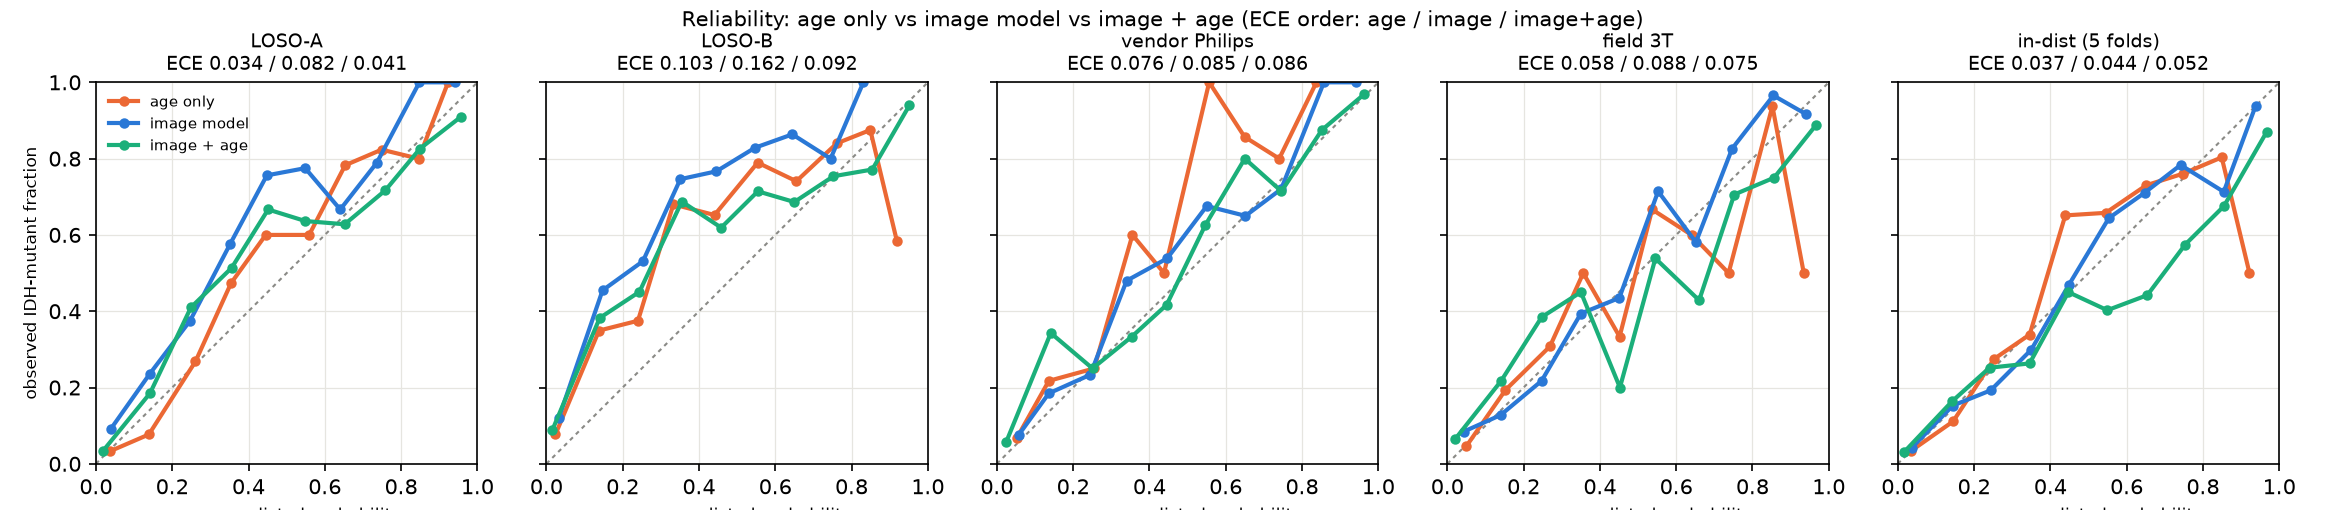

In [6]:
fig = abc.plot(rows, Path(out_fig))
plt.close(fig)
display(Image(filename=out_fig))

## 4. 読み方

結論はこのセルの上の数字から書く。見るべき点：

1. **分布外で、年齢のみの ECE は画像モデルより小さいか**。小さいなら「年齢は判別だけでなく較正もシフトに強い」と言える
2. **年齢のみの較正切片**：LOSO-B では既存の結果から +0.5 前後（予測平均 19.5% 対 実際 28.4%）が予想される。
   年齢で説明できない有病率差は、年齢モデルにも切片ずれとして残るはず
3. **較正スロープ**：画像モデルは 1 未満（過信）か。年齢モデルは 1 近くか
4. **画像 + 年齢**：AUC と同じく、ECE も両方の単独より良くなるか。それとも足し算で過信が強まるか（スロープ < 1）

## 5. 保存

In [7]:
res = {"params": {"boot_reps": boot_reps, "runs_dir": runs_dir}, "checks": checks,
       "units": rows, "summary": summ}
Path(out_json).write_text(json.dumps(res, indent=2, ensure_ascii=False, default=float))
md_text = "# 年齢のみ・画像モデル・画像 + 年齢の較正 — 結果要約\n\n"
md_text += (f"検算：AUC は age_prior.json の auc_table と一致（最大差 {d_auc:.0e}）。"
            f"predictions.csv は全 9 ユニット × 3 seed。\n\n")
md_text += abc.tables_md(rows, summ) + "\n"
Path(out_md).write_text(md_text)
print("wrote", out_json, out_md, out_fig)

wrote results/age_baseline_calibration.json results/age_baseline_calibration.md results/figures/age_baseline_reliability.png
